In [1]:
#check that the virtual environment is running 
import sys
print(sys.executable)

/mnt/c/Users/manzoni/Desktop/FITS/myvenv/bin/python


In [5]:
# Machine Learning and Radio Astronomy
#
# Example:
# Can machine learning recover the position of the Sun
# from a radio telescope drift scan?
#
# Telescope measurements:
# JD = Julian Date
# RHCP = Right-Hand Circular Polarization
# LHCP = Left-Hand Circular Polarization
#
# Derived quantities:
#
# I = RHCP + LHCP
# V = RHCP - LHCP

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
plt.rcParams["figure.figsize"] = (10,5)
#my import
from radio_utilities import *
import json
import urllib.request
import pandas as pd
import time
import io
from zoneinfo import ZoneInfo
from astropy.time import Time

In [8]:
with fits.open('../data/20260807/20260807_RT1.fits') as hdul:
    astro_table = Table(hdul[1].data)
    RT1 = astro_table.to_pandas()

RT1 = RT1[RT1['JD']<2461260.786666668]

print(RT1.columns)
df = RT1[['JD','RIGHT_POL','LEFT_POL']]
df.head()

DIAMETER =                    0  / TELESCOPE diameter                            [astropy.io.fits.card]


Index(['JD', 'Azimuth', 'Elevation', 'Az_Offset', 'El_Offset', 'Gal_Long',
       'Gal_Lat', 'LEFT_POL', 'RIGHT_POL', 'LEFT_FILT', 'RIGHT_FILT', 'BBC02u',
       'BBC03u', 'BBC04u', 'BBC05u', 'BBC06u', 'BBC10u', 'BBC11u', 'BBC13u',
       'BBC14u', 'CAL', 'MARKER'],
      dtype='str')


,JD,RIGHT_POL,LEFT_POL
0,2.461260e+06,45,22
1,2.461260e+06,45,22
2,2.461260e+06,45,22
3,2.461260e+06,45,22
4,2.461260e+06,45,22


In [9]:
# Stokes parameters
df["I"] = df["RIGHT_POL"] + df["LEFT_POL"]
df["V"] = df["RIGHT_POL"] - df["LEFT_POL"]

In [10]:
#print(1*df['JD'].mean())
# cut at this value: 2461260.786666668

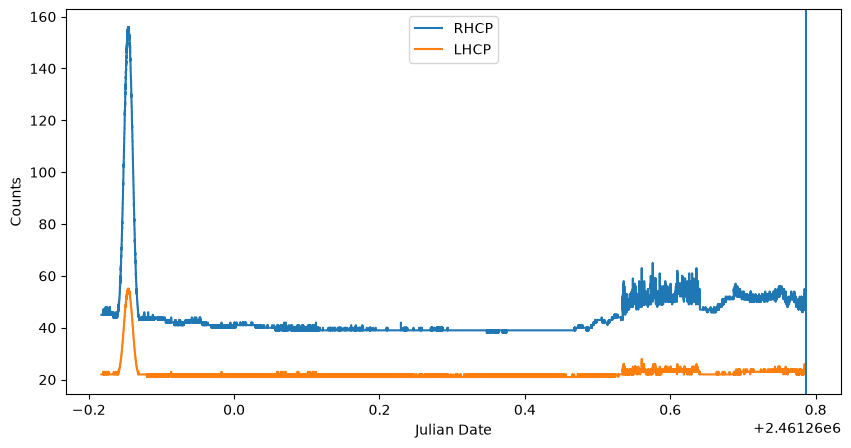

In [11]:
plt.plot(df["JD"], df["RIGHT_POL"], label="RHCP")
plt.plot(df["JD"], df["LEFT_POL"], label="LHCP")
plt.xlabel("Julian Date")
plt.ylabel("Counts")
plt.legend()
plt.axvline(2461260.786666668)
plt.show()

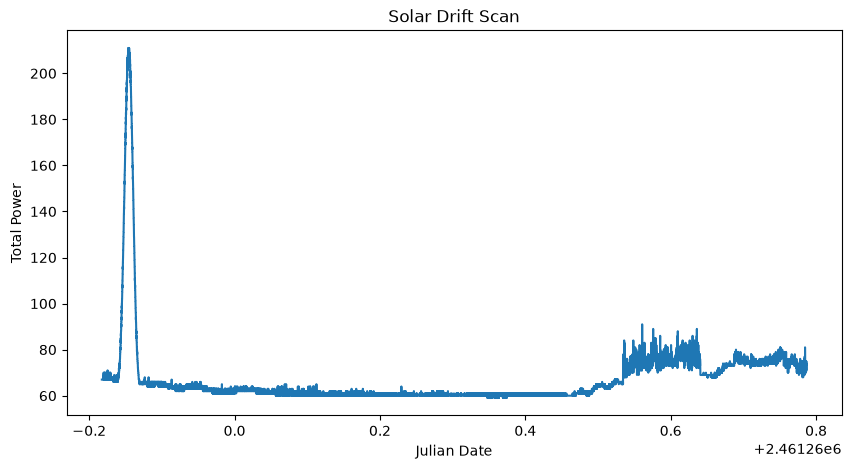

In [12]:
plt.plot(df["JD"], df["I"])
plt.xlabel("Julian Date")
plt.ylabel("Total Power")
plt.title("Solar Drift Scan")
plt.show()

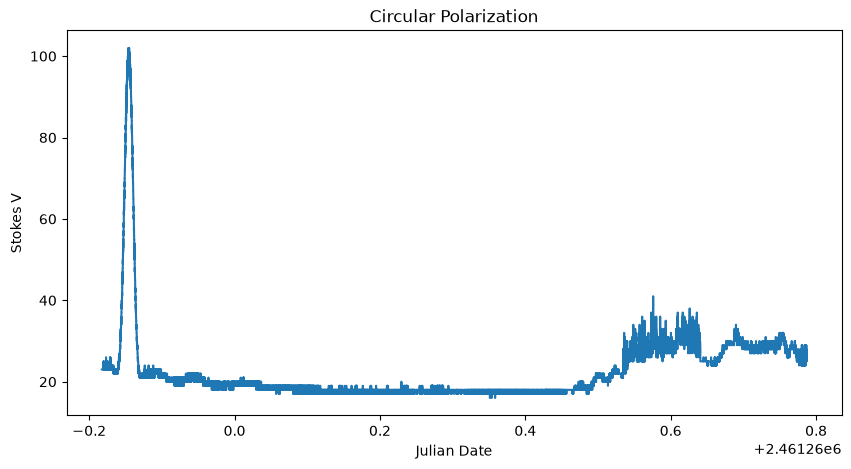

In [13]:
plt.plot(df["JD"], df["V"])
plt.xlabel("Julian Date")
plt.ylabel("Stokes V")
plt.title("Circular Polarization")
plt.show()

In [14]:
df["TIME_SEC"] = (
df["JD"] - df["JD"].iloc[0]
) * 86400

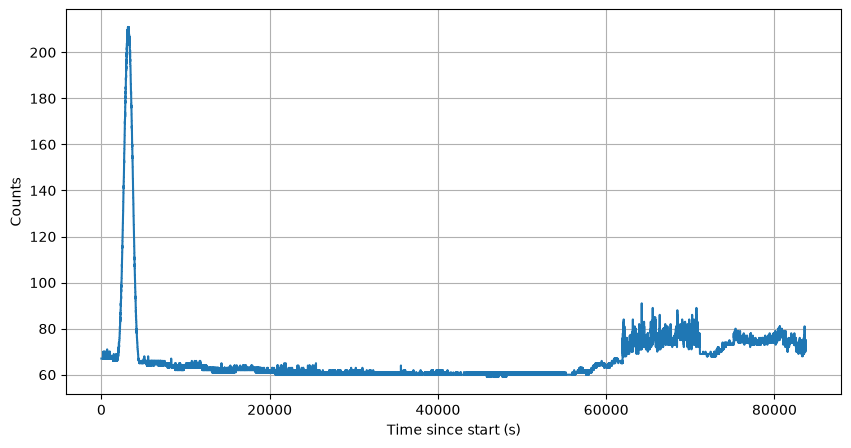

In [15]:
plt.plot(df["TIME_SEC"], df["I"])
plt.xlabel("Time since start (s)")
plt.ylabel("Counts")
plt.grid()
plt.show()

In [16]:
def gaussian(t, A, mu, sigma, C):

    return A * np.exp(
        -(t - mu)**2 / (2 * sigma**2)
    ) + C

In [17]:
A0 = df["I"].max() - df["I"].min()

mu0 = df.loc[
    df["I"].idxmax(),
    "TIME_SEC"
]

sigma0 = 100

C0 = df["I"].min()

print("Initial estimate =", mu0, "s")

Initial estimate = 3157.158011198044 s


In [18]:
popt, pcov = curve_fit(
gaussian,
df["TIME_SEC"],
df["I"],
p0=[A0, mu0, sigma0, C0]
)
A_fit, mu_fit, sigma_fit, C_fit = popt

In [19]:
print(f"Transit time = {mu_fit:.1f} s")
print(f"Sigma = {sigma_fit:.1f} s")
print(f"Peak amplitude = {A_fit:.1f} counts")

Transit time = 3195.2 s
Sigma = 479.5 s
Peak amplitude = 147.4 counts


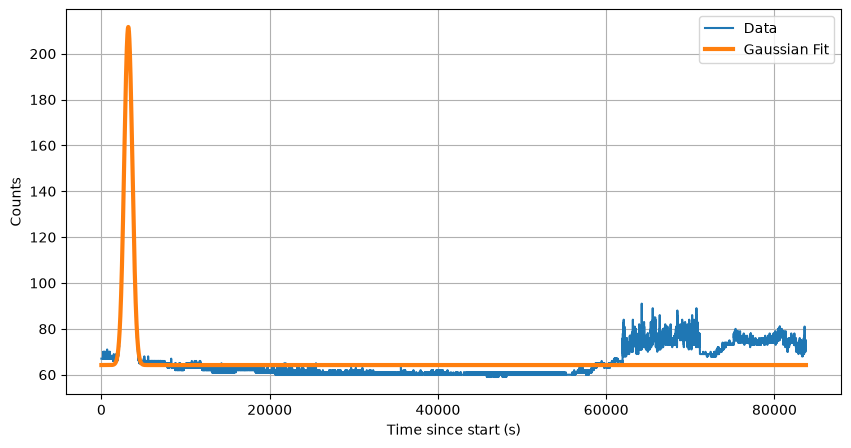

In [20]:
best_fit = gaussian(
    df["TIME_SEC"],
    *popt
)

plt.plot(
    df["TIME_SEC"],
    df["I"],
    label="Data"
)

plt.plot(
    df["TIME_SEC"],
    best_fit,
    linewidth=3,
    label="Gaussian Fit"
)

plt.xlabel("Time since start (s)")
plt.ylabel("Counts")

plt.legend()
plt.grid()

plt.show()

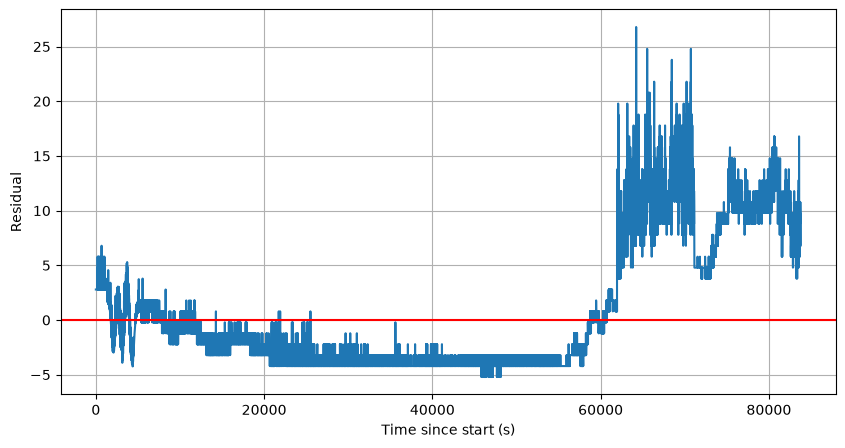

In [21]:
residuals = df["I"] - best_fit

plt.plot(
    df["TIME_SEC"],
    residuals
)

plt.axhline(
    0,
    color="red"
)

plt.xlabel("Time since start (s)")
plt.ylabel("Residual")

plt.grid()

plt.show()

In [22]:
fwhm_sec = 2.355 * sigma_fit

print(f"FWHM = {fwhm_sec:.1f} s")

FWHM = 1129.3 s


In [23]:
beam_deg = fwhm_sec * 15 / 3600

print(f"Beam FWHM = {beam_deg:.2f} degrees")

Beam FWHM = 4.71 degrees


In [24]:
base_scan = df["I"].values

X = []
y = []

for i in range(5000):

    shift = np.random.randint(-20, 21)

    shifted = np.roll(
        base_scan,
        shift
    )

    noise = np.random.normal(
        0,
        0.05*np.std(base_scan),
        len(base_scan)
    )

    sample = shifted + noise

    X.append(sample)

    y.append(shift)

X = np.array(X)
y = np.array(y)

print(X.shape)

(5000, 109129)


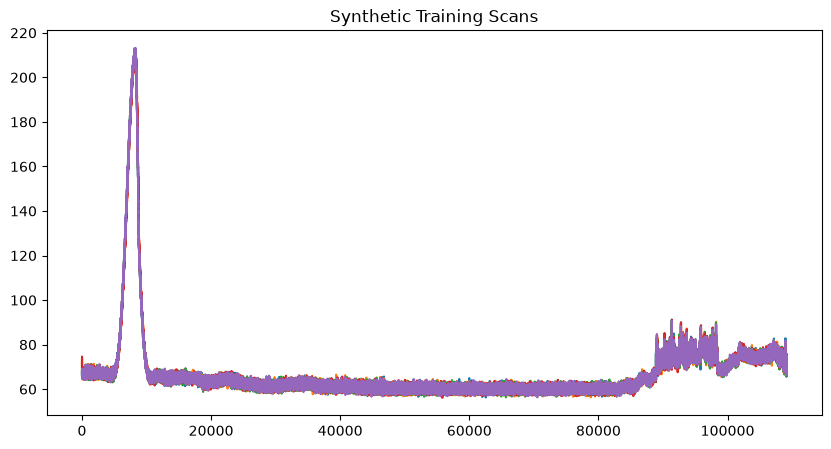

In [25]:
for i in range(5):
    plt.plot(X[i])
plt.title("Synthetic Training Scans")
plt.show()

In [ ]:
Xtrain, Xtest, ytrain, ytest = train_test_split(
X,
y,
test_size=0.2,
random_state=42
)

In [ ]:
# train random forest
rf = RandomForestRegressor(
n_estimators=200,
random_state=42
)
 
rf.fit(
Xtrain,
ytrain
)

In [ ]:
# Evaluate 
pred = rf.predict(Xtest)

mae = mean_absolute_error(
    ytest,
    pred
)

print("Mean Absolute Error =", mae)

In [ ]:
#Prediction accuracy 
plt.scatter(
    ytest,
    pred,
    alpha=0.4
)

plt.plot(
    [-20,20],
    [-20,20],
    "r"
)

plt.xlabel("True Shift")
plt.ylabel("Predicted Shift")

plt.grid()

plt.show()